# Imports General

In [166]:
import pandas as pd
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt
import seaborn as sns

# Ficha Técnica

**Archivo de origen:** clientes_banca_raw.csv
* **Dimensiones brutas:** 600 filas y 15 columnas
* **Unidad de análisis:** Cada fila contiene la información de un cliente individual del banco
* **Variable objetivo detectada:** Abandono, ya que el objetivo es saber si un cliente va a salirse del banco o no
* **Naturaleza del problema:** Clasificación Binaria


# Fase 1: Estudio Inicial

## Carga de Datos

In [167]:
archivo1 = "clientes_banca_raw.csv"
df = pd.read_csv(archivo1)

In [168]:
# Muestra los 10 primeros registros para tenerlos de ejemplo de como esta hecho el fichero
df.head(10)

,id_cliente,edad,ingresos_anuales,salario_mensual_aprox,antiguedad_meses,saldo_cuenta,nivel_estudios,tipo_cuenta,nivel_satisfaccion,num_productos,tiene_tarjeta,canal_preferido,comentarios_cliente,motivo_cancelacion,abandono
0,CLI-1001,40.0,13714.71,1140.25,11.0,0.00,Grado,Corriente,Medio,2,0,App Movil,NaN,Mejor oferta competidor,1
1,CLI-1002,39.0,13334.98,1081.97,31.0,4586.66,Grado,Ahorro,Alto,2,1,App Movil,NaN,NaN,0
2,CLI-1003,40.0,21279.05,1748.91,93.0,0.00,Secundaria,Corriente,Bajo,1,1,Oficina,NaN,Cambio de residencia,1
3,CLI-1004,50.0,19778.29,1669.12,53.0,146281.94,Primaria,Ahorro,Bajo,1,0,App Movil,NaN,NaN,0
4,CLI-1005,40.0,15492.14,1289.58,63.0,16880.38,Primaria,Nomina,Medio,1,1,Web,NaN,NaN,0
5,CLI-1006,NaN,33363.64,2799.66,72.0,0.00,Doctorado,Corriente,Muy Bajo,1,1,App Movil,NaN,Comisiones abusivas,1
6,CLI-1007,45.0,26327.41,2114.89,98.0,0.00,Grado,Ahorro,Muy Alto,2,1,Oficina,NaN,NaN,0
7,CLI-1008,38.0,22150.40,1873.62,31.0,0.00,NaN,Ahorro,Medio,3,0,App Movil,NaN,Mejor oferta competidor,1
8,CLI-1009,39.0,21833.75,1807.13,89.0,762.03,Secundaria,Corriente,Bajo,2,1,App Movil,NaN,NaN,0
9,CLI-1010,43.0,55093.98,4645.49,61.0,10359.32,Grado,Ahorro,Medio,2,0,App Movil,NaN,NaN,0


## Resumen de Estructura e Informacion del Dataframe

In [169]:
# Numero de filas y columnas
df.shape

(600, 15)

## Identificadores

In [170]:
# Columnas que no cambiarían el comportamiento ya que no te necesitas saber el id si tu objetivo es saber si el cliente abandonará o no el banco
df = df.drop(['id_cliente'], axis=1)

## Partición Train / Test

In [171]:
X = df.drop('abandono', axis=1)
Y = df['abandono']

In [172]:
# Dividimos la X e Y anterior para poder tener train y test de cada una de ellas
X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size=0.2, random_state=42)

In [173]:
# Dimensiones de X
X_train.shape, X_test.shape

((480, 13), (120, 13))

In [174]:
# Dimensiones de Y
Y_train.shape, Y_test.shape

((480,), (120,))

## Verificación de Integridad

In [175]:
# Da como resultado 600 y 480 + 120. Por lo que si coincide el total de X con el train y test de X
X.shape[0], X_train.shape[0], X_test.shape[0]

(600, 480, 120)

## Blindaje y Persistencia

In [176]:
# Guardado de datos para conservarlos por separado
X_train.to_csv("datos_train_X.csv", index=False)
Y_train.to_csv("datos_train_y.csv", index=False)
X_test.to_csv("datos_test_X.csv", index=False)
Y_test.to_csv("datos_test_y.csv", index=False)

# Fase 2: Estudio Univariante

## Criba Inicial

In [177]:
# Tabla de Auditoría
auditoria = pd.DataFrame({
'tipo': X_train.dtypes,
'nulos': X_train.isna().sum(),
'pct_nulos': (X_train.isna().mean() * 100).round(2),
'cardinalidad': X_train.nunique()
})
print(auditoria)
print("\nFilas duplicadas en X_train:", X_train.duplicated().sum())

                          tipo  nulos  pct_nulos  cardinalidad
edad                   float64      6       1.25            55
ingresos_anuales       float64      7       1.46           471
salario_mensual_aprox  float64      7       1.46           473
antiguedad_meses       float64      5       1.04           114
saldo_cuenta           float64      0       0.00           409
nivel_estudios          object      6       1.25             5
tipo_cuenta             object      0       0.00             8
nivel_satisfaccion      object      0       0.00             5
num_productos            int64      0       0.00             4
tiene_tarjeta            int64      0       0.00             2
canal_preferido         object      0       0.00             5
comentarios_cliente     object    475      98.96             5
motivo_cancelacion      object    284      59.17             4

Filas duplicadas en X_train: 0


**Columnas a Estudiar con Detenimiento**

edad, ingresos_mensuales, salario_mensual_aprox, antiguedad_meses y nivel_estudios habría que estudiarlos porque tiene datos que son nulos y pueden dar problemas al hacer los modelos ya que añadiria datos basura

**Columnas que Habria que Descartar**

comentarios_cliente ya que la mayoria de sus datos son nulos y no aportan nada a los modelos

**Diagnóstico de Variables Numéricas**

Variables numéricas serian: edad, ingresos_anuales, salario_mensual_aprox, antiguedad_meses y saldo_cuenta

**Diagnóstico de Variables Categóricas**

Variables categóricas serian: nivel_estudios, tipo_cuenta, nivel_satisfaccion, num_productos, tiene_tarjeta, canal_preferido, comentarios_cliente y motivo_cancelacion

## Análisis Variables Numéricas

**Columna Edad**

In [178]:
# Resumen Estadístico
X_train['edad'].describe()

,edad
count,474.000000
mean,46.491561
std,63.655097
min,18.000000
25%,34.000000
50%,42.000000
75%,50.000000
max,999.000000


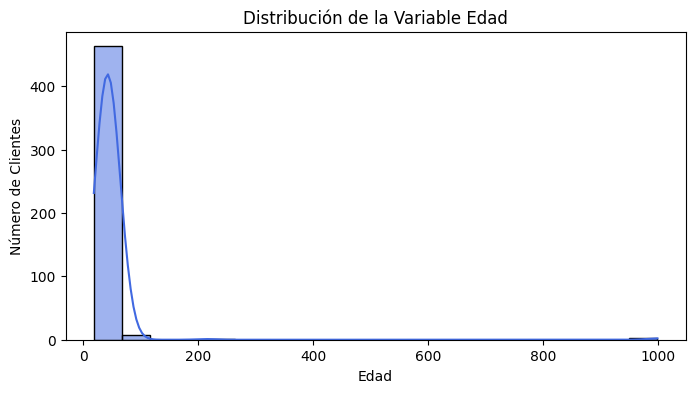

In [179]:
# Histograma KDE
plt.figure(figsize=(8, 4))
sns.histplot(data=X_train, x='edad', bins=20, kde=True, color='royalblue')
plt.title("Distribución de la Variable Edad")
plt.xlabel("Edad")
plt.ylabel("Número de Clientes")
plt.show()

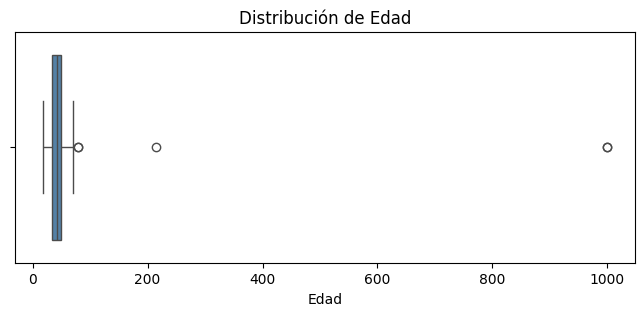

In [180]:
# Histograma Boxplot
plt.figure(figsize=(8, 3))
sns.boxplot(x=X_train['edad'], color='steelblue')
plt.title("Distribución de Edad")
plt.xlabel("Edad")
plt.show()

V (Visualización): Observo cuál es el rango de edad de los clientes del banco.

H (Hallazgo): Veo que la mediana se sitúa en los 42 años, mientras que la media sube a 46 años porque hay valores muy diferentes, como un cliente que tiene 999 años y estira la gráfica. El 75% de los clientes tiene menos de 50 años. Además, encuentro algunas filas vacías sin edad.

A (Acción para Preprocesamiento): Voy a borrar la edad imposible de 999 años y rellenaré los huecos vacíos con la media para que los datos queden bien.

**Columna Ingresos Anuales**

In [181]:
# Resumen Estadístico
X_train['ingresos_anuales'].describe()

,ingresos_anuales
count,473.000000
mean,30486.062748
std,24389.598616
min,0.000000
25%,19531.920000
50%,27087.990000
75%,36215.430000
max,345000.000000


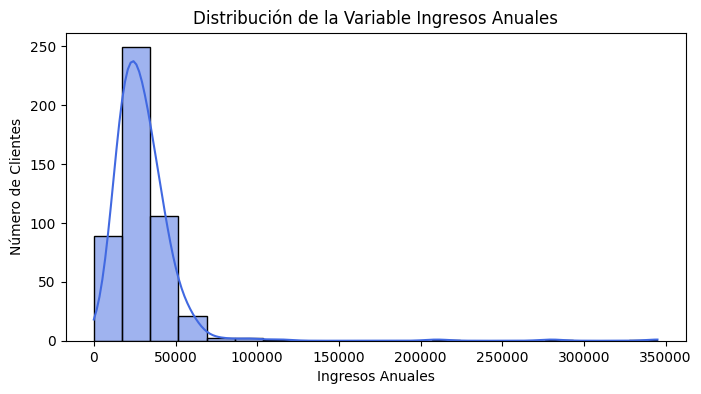

In [182]:
# Histograma KDE
plt.figure(figsize=(8, 4))
sns.histplot(data=X_train, x='ingresos_anuales', bins=20, kde=True, color='royalblue')
plt.title("Distribución de la Variable Ingresos Anuales")
plt.xlabel("Ingresos Anuales")
plt.ylabel("Número de Clientes")
plt.show()

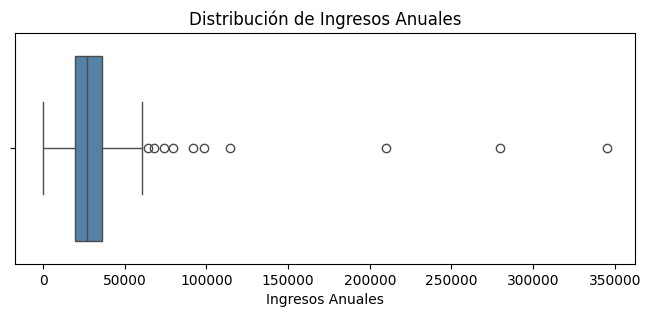

In [183]:
# Histograma Boxplot
plt.figure(figsize=(8, 3))
sns.boxplot(x=X_train['ingresos_anuales'], color='steelblue')
plt.title("Distribución de Ingresos Anuales")
plt.xlabel("Ingresos Anuales")
plt.show()

V (Visualización): Observo cuál es el rango de ingresos anuales que ganan los clientes del banco.

H (Hallazgo): Veo que la mediana está en unos 27.088 € y la media sube a 30.486 € porque hay personas que ganan muchísimo dinero y estiran la gráfica hacia la derecha. El 75% de los clientes gana menos de 36.215 €. También encuentro 7 huecos vacíos, algunos clientes con 0 € y noto que es prácticamente idéntico al salario mensual.

A (Acción para Preprocesamiento): Rellenaré los huecos vacíos con la mediana para que los datos estén bien y no se desvíen por los sueldos altos. Además, revisaré los clientes que tienen 0 € y eliminaré la columna de salario mensual para no repetir información.

**Columna Salario Mensual Aprox**

In [184]:
# Resumen Estadístico
X_train['salario_mensual_aprox'].describe()

,salario_mensual_aprox
count,473.000000
mean,2540.781311
std,2034.262138
min,-20.670000
25%,1611.010000
50%,2241.150000
75%,3027.250000
max,28754.830000


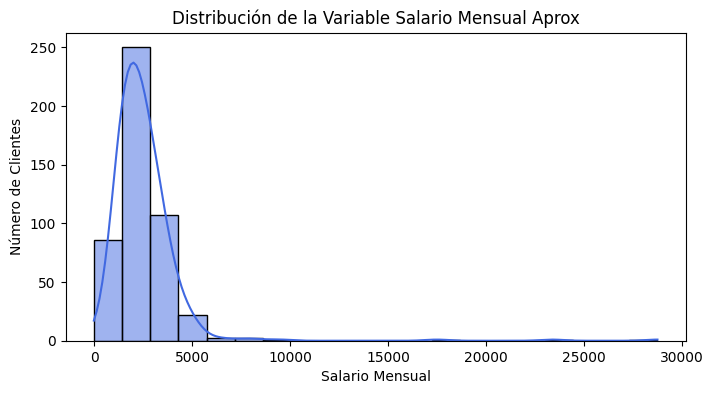

In [185]:
# Histograma KDE
plt.figure(figsize=(8, 4))
sns.histplot(data=X_train, x='salario_mensual_aprox', bins=20, kde=True, color='royalblue')
plt.title("Distribución de la Variable Salario Mensual Aprox")
plt.xlabel("Salario Mensual")
plt.ylabel("Número de Clientes")
plt.show()

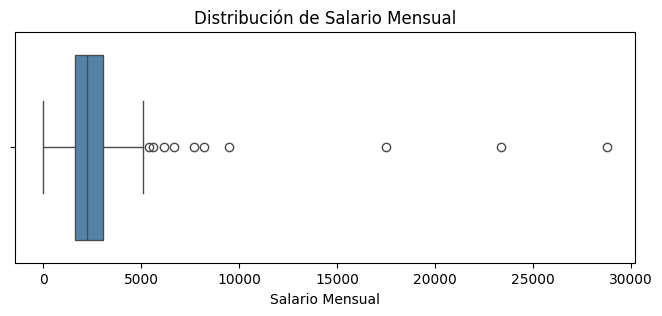

In [186]:
# Histograma Boxplot
plt.figure(figsize=(8, 3))
sns.boxplot(x=X_train['salario_mensual_aprox'], color='steelblue')
plt.title("Distribución de Salario Mensual")
plt.xlabel("Salario Mensual")
plt.show()

V (Visualización): Observo cuánto cobran al mes aproximadamente los clientes.

H (Hallazgo): Veo que la mediana del sueldo mensual está en 2.241 € y la media sube a 2.541 € por salarios muy altos. El 75% cobra menos de 3.027 € al mes. Encuentro 7 huecos vacíos y veo cantidades negativas que no tienen ningún sentido. Además, veo que aporta exactamente la misma información que los ingresos anuales.

A (Acción para Preprocesamiento): Quito esta columna directamente porque ya tengo los ingresos anuales y esta solo me daría información repetida. Si tuviera que mantenerla, corregiría los números negativos y rellenaría los huecos vacíos con la mediana.

**Columna Antiguedad Meses**

In [187]:
# Resumen Estadístico
X_train['antiguedad_meses'].describe()

,antiguedad_meses
count,475.000000
mean,60.997895
std,32.804851
min,1.000000
25%,34.000000
50%,61.000000
75%,88.000000
max,120.000000


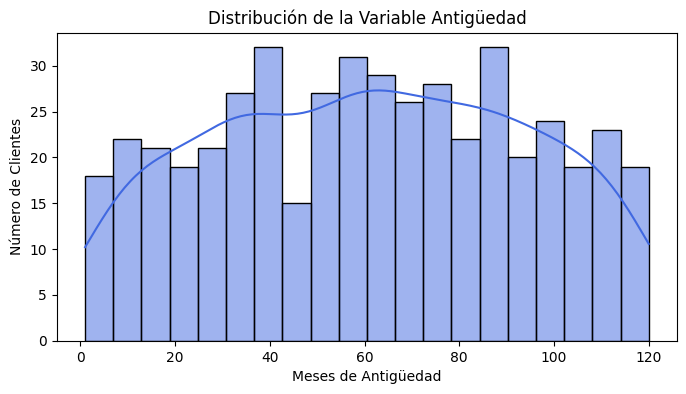

In [188]:
# Histograma KDE
plt.figure(figsize=(8, 4))
sns.histplot(data=X_train, x='antiguedad_meses', bins=20, kde=True, color='royalblue')
plt.title("Distribución de la Variable Antigüedad")
plt.xlabel("Meses de Antigüedad")
plt.ylabel("Número de Clientes")
plt.show()

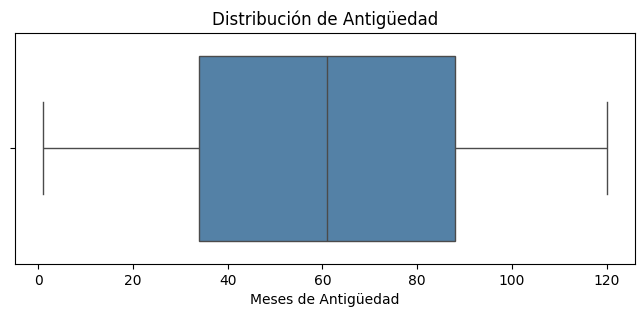

In [189]:
# Histograma Boxplot
plt.figure(figsize=(8, 3))
sns.boxplot(x=X_train['antiguedad_meses'], color='steelblue')
plt.title("Distribución de Antigüedad")
plt.xlabel("Meses de Antigüedad")
plt.show()

V (Visualización): Observo cuánto tiempo llevan los clientes con nosotros en el banco.

H (Hallazgo): Compruebo que la mediana y la media coinciden casi exactas en unos 61 meses, lo que me demuestra que los clientes están muy bien repartidos entre 1 y 120 meses. El 75% lleva menos de 88 meses. No encuentro valores raros ni extremos, pero sí localizo 5 filas vacías.

A (Acción para Preprocesamiento): Rellenaré los huecos que faltan con la mediana para mantener la coherencia y no perder los datos de esos clientes.

**Columna Saldo Cuenta**

In [190]:
# Resumen Estadístico
X_train['saldo_cuenta'].describe()

,saldo_cuenta
count,480.000000
mean,12913.804354
std,20154.333978
min,0.000000
25%,2070.052500
50%,5810.565000
75%,16597.400000
max,238703.860000


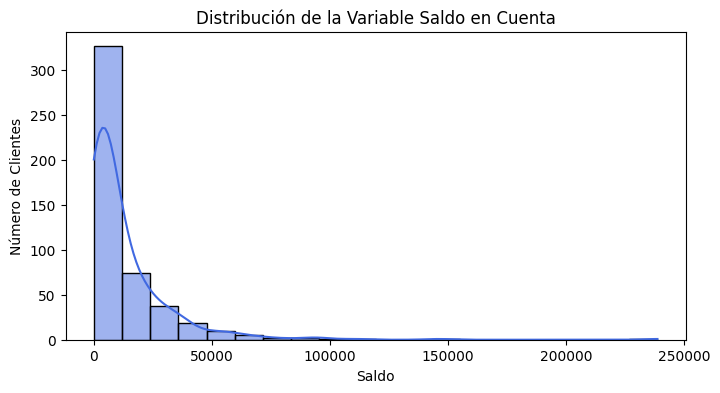

In [191]:
# Histograma KDE
plt.figure(figsize=(8, 4))
sns.histplot(data=X_train, x='saldo_cuenta', bins=20, kde=True, color='royalblue')
plt.title("Distribución de la Variable Saldo en Cuenta")
plt.xlabel("Saldo")
plt.ylabel("Número de Clientes")
plt.show()

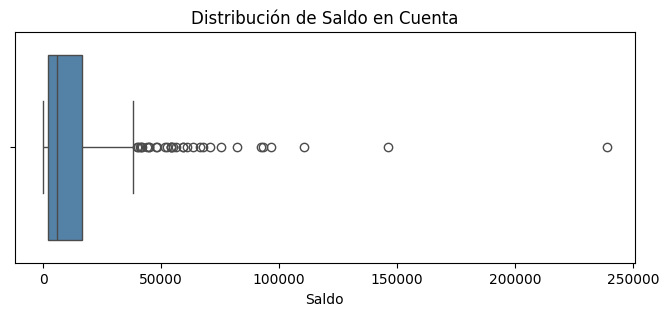

In [192]:
# Histograma Boxplot
plt.figure(figsize=(8, 3))
sns.boxplot(x=X_train['saldo_cuenta'], color='steelblue')
plt.title("Distribución de Saldo en Cuenta")
plt.xlabel("Saldo")
plt.show()

V (Visualización): Observo qué cantidad de dinero tienen guardada los clientes en su cuenta.

H (Hallazgo): Veo que la mediana del saldo está en 5.811 €, pero la media se dispara a 12.914 € porque hay clientes con muchísimo dinero. El 75% de los clientes tiene menos de 16.597 €. Noto que hay bastantes clientes con la cuenta a 0 €. En esta columna no encuentro ningún hueco vacío.

A (Acción para Preprocesamiento): Al no haber huecos vacíos no tengo que rellenar nada. Como existe una diferencia grande entre los saldos normales y los más ricos, escalaré la variable usando un método robusto para que esos números tan altos no descompensen el modelo.

## Análisis Variables Categóricas


**Columna Nivel de Estudios**


In [193]:
# Inspeccionar valores únicos
print("Valores distintos:", X_train['nivel_estudios'].unique())
print("Número de categorías:", X_train['nivel_estudios'].nunique())

# Porcentaje de aparición de cada categoría
X_train['nivel_estudios'].value_counts(dropna=False, normalize=True) * 100

Valores distintos: ['Secundaria' 'Grado' 'Doctorado' nan 'Primaria' 'Master']
Número de categorías: 5


,proportion
nivel_estudios,
Grado,33.958333
Secundaria,32.500000
Master,14.166667
Primaria,13.125000
Doctorado,5.000000
NaN,1.250000


/tmp/ipykernel_3802/3367440310.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=X_train, y='nivel_estudios', order=X_train['nivel_estudios'].value_counts().index, palette='mako')


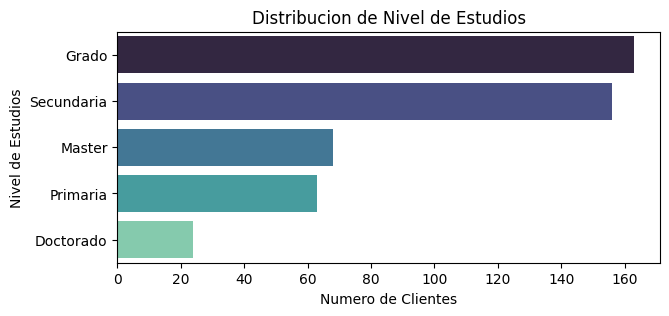

In [194]:
# Grafico de barras
plt.figure(figsize=(7, 3))
sns.countplot(data=X_train, y='nivel_estudios', order=X_train['nivel_estudios'].value_counts().index, palette='mako')
plt.title("Distribucion de Nivel de Estudios")
plt.xlabel("Numero de Clientes")
plt.ylabel("Nivel de Estudios")
plt.show()

V (Visualización): Observo cuál es el nivel de estudios que tienen los clientes del banco.

H (Hallazgo): Compruebo que la mayoría de los clientes tiene Grado o Secundaria, seguidos de Máster, Primaria y Doctorado. Veo que los nombres de las categorías están bien escritos y no encuentro errores, pero localizo 6 filas vacías.

A (Acción para Preprocesamiento): Rellenaré los huecos vacíos usando la categoría más frecuente, que es Grado. Como los estudios siguen una jerarquía, convertiré los niveles en números del 1 al 5 desde Primaria hasta Doctorado.

**Columna Tipo de Cuenta**


In [195]:
# Inspeccionar valores únicos
print("Valores distintos:", X_train['tipo_cuenta'].unique())
print("Número de categorías:", X_train['tipo_cuenta'].nunique())

# Porcentaje de aparición de cada categoría
X_train['tipo_cuenta'].value_counts(dropna=False, normalize=True) * 100

Valores distintos: ['Nomina' 'Ahorro' 'Corriente' 'Inversion' '?' 'nomina ' 'AHORRO'
 ' Ahorro']
Número de categorías: 8


,proportion
tipo_cuenta,
Corriente,46.875000
Ahorro,31.250000
Nomina,17.083333
Inversion,3.958333
?,0.208333
nomina,0.208333
AHORRO,0.208333
Ahorro,0.208333


/tmp/ipykernel_3802/1444543464.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=X_train, y='tipo_cuenta', order=X_train['tipo_cuenta'].value_counts().index, palette='mako')


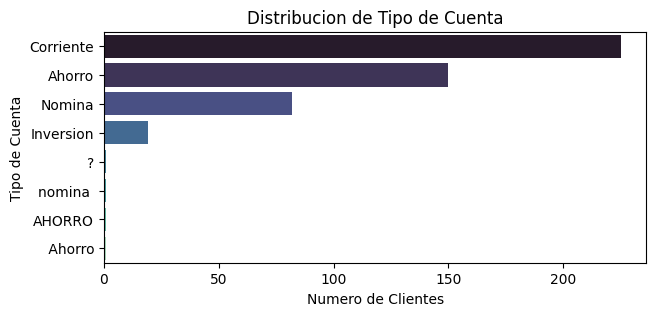

In [196]:
# Grafico de barras
plt.figure(figsize=(7, 3))
sns.countplot(data=X_train, y='tipo_cuenta', order=X_train['tipo_cuenta'].value_counts().index, palette='mako')
plt.title("Distribucion de Tipo de Cuenta")
plt.xlabel("Numero de Clientes")
plt.ylabel("Tipo de Cuenta")
plt.show()

V (Visualización): Observo cuáles son las cuentas más contratadas y si los textos son coherentes.

H (Hallazgo): Veo que la cuenta Corriente es la que tiene la mayoría, seguida de Ahorro, Nómina e Inversión. Veo fallos claros en los textos, como palabras escritas en minúsculas, espacios en blanco sobrantes y un signo de interrogación en una de las filas.

A (Acción para Preprocesamiento): Limpiaré los textos quitando los espacios sobrantes y las mayúsculas para no tener cuentas repetidas. Reemplazaré el signo de interrogación por la cuenta más común y crearé una columna para cada tipo de cuenta.

**Columna Nivel de Satisfacción**


In [197]:
# Inspeccionar valores únicos
print("Valores distintos:", X_train['nivel_satisfaccion'].unique())
print("Número de categorías:", X_train['nivel_satisfaccion'].nunique())

# Porcentaje de aparición de cada categoría
X_train['nivel_satisfaccion'].value_counts(dropna=False, normalize=True) * 100

Valores distintos: ['Medio' 'Alto' 'Muy Bajo' 'Muy Alto' 'Bajo']
Número de categorías: 5


,proportion
nivel_satisfaccion,
Medio,35.625000
Alto,21.666667
Bajo,21.041667
Muy Bajo,12.916667
Muy Alto,8.750000


/tmp/ipykernel_3802/4076271611.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=X_train, y='nivel_satisfaccion', order=X_train['nivel_satisfaccion'].value_counts().index, palette='mako')


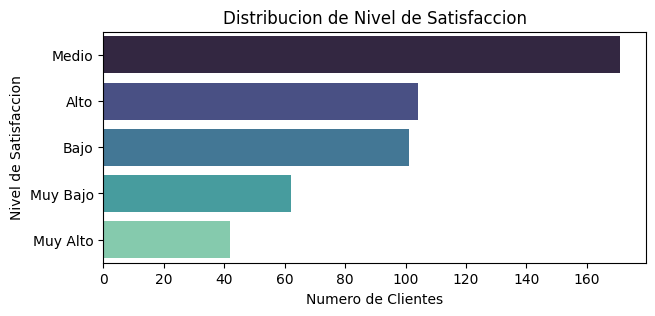

In [198]:
# Grafico de barras
plt.figure(figsize=(7, 3))
sns.countplot(data=X_train, y='nivel_satisfaccion', order=X_train['nivel_satisfaccion'].value_counts().index, palette='mako')
plt.title("Distribucion de Nivel de Satisfaccion")
plt.xlabel("Numero de Clientes")
plt.ylabel("Nivel de Satisfaccion")
plt.show()

V (Visualización): Observo el grado de contento o satisfacción que expresan los clientes con el banco.

H (Hallazgo): Veo que la opción más común es Medio, seguida de Alto y Bajo, siendo Muy Bajo y Muy Alto las menos frecuentes. Compruebo que los textos están limpios y no encuentro ninguna fila con valores nulos.

A (Acción para Preprocesamiento): No necesito rellenar ningún dato porque no hay valores nulos. Al tener un orden lógico, transformaré estas categorías en números ordenados de menor a mayor satisfacción.

**Columna Canal Preferido**


In [199]:
# Inspeccionar valores únicos
print("Valores distintos:", X_train['canal_preferido'].unique())
print("Número de categorías:", X_train['canal_preferido'].nunique())

# Porcentaje de aparición de cada categoría
X_train['canal_preferido'].value_counts(dropna=False, normalize=True) * 100

Valores distintos: ['Oficina' 'App Movil' 'Web' 'Telefono' 'Cajero Antiguo']
Número de categorías: 5


,proportion
canal_preferido,
App Movil,50.416667
Web,24.166667
Oficina,15.833333
Telefono,8.750000
Cajero Antiguo,0.833333


/tmp/ipykernel_3802/425037109.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=X_train, y='canal_preferido', order=X_train['canal_preferido'].value_counts().index, palette='mako')


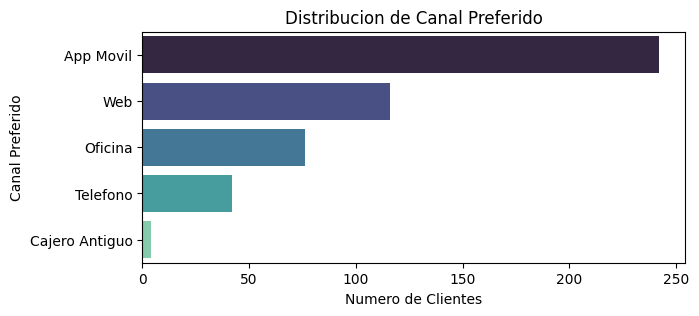

In [200]:
# Grafico de barras
plt.figure(figsize=(7, 3))
sns.countplot(data=X_train, y='canal_preferido', order=X_train['canal_preferido'].value_counts().index, palette='mako')
plt.title("Distribucion de Canal Preferido")
plt.xlabel("Numero de Clientes")
plt.ylabel("Canal Preferido")
plt.show()

V (Visualización): Observo cuál es la vía preferida por los clientes para operar con la entidad.

H (Hallazgo): Veo que la App Móvil es la favorita de la mitad de los clientes, seguida de la Web y la Oficina física. El Teléfono y el Cajero Antiguo son las opciones que menos se utilizan. No encuentro ningún dato vacío y veo que los nombres están bien escritos.

A (Acción para Preprocesamiento): No tengo que rellenar nada. Al tratarse de opciones sin ningún orden, pondré cada canal en una columna separada.

**Columna Número de Productos**


In [201]:
# Inspeccionar valores únicos
print("Valores distintos:", X_train['num_productos'].unique())
print("Número de categorías:", X_train['num_productos'].nunique())

# Porcentaje de aparición de cada categoría
X_train['num_productos'].value_counts(dropna=False, normalize=True) * 100

Valores distintos: [2 3 1 4]
Número de categorías: 4


,proportion
num_productos,
2,42.708333
1,38.125000
3,14.583333
4,4.583333


/tmp/ipykernel_3802/2539349424.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=X_train, y='num_productos', order=X_train['num_productos'].value_counts().index, palette='mako')


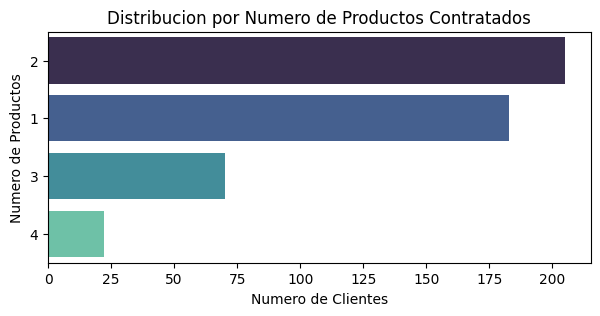

In [202]:
# Grafico de barras
plt.figure(figsize=(7, 3))
sns.countplot(data=X_train, y='num_productos', order=X_train['num_productos'].value_counts().index, palette='mako')
plt.title("Distribucion por Numero de Productos Contratados")
plt.xlabel("Numero de Clientes")
plt.ylabel("Numero de Productos")
plt.show()

V (Visualización): Observo cuántos productos bancarios distintos tiene contratados cada cliente.

H (Hallazgo): Veo que la mayoría de los clientes tiene 2 productos o 1 producto. Con 3 productos tienen un porcentaje menor y con 4 productos muy pocos. Veo que todos los números están dentro de lo normal y no veo ningún valor nulo.

A (Acción para Preprocesamiento): Al no haber valores nulos no tengo que rellenar nada y mantendré la columna tal cual con sus valores numéricos originales.

**Columna Tiene Tarjeta**


In [203]:
# Inspeccionar valores únicos
print("Valores distintos:", X_train['tiene_tarjeta'].unique())
print("Número de categorías:", X_train['tiene_tarjeta'].nunique())

# Porcentaje de aparición de cada categoría
X_train['tiene_tarjeta'].value_counts(dropna=False, normalize=True) * 100

Valores distintos: [1 0]
Número de categorías: 2


,proportion
tiene_tarjeta,
1,68.541667
0,31.458333


/tmp/ipykernel_3802/927062812.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=X_train, y='tiene_tarjeta', order=X_train['tiene_tarjeta'].value_counts().index, palette='mako')


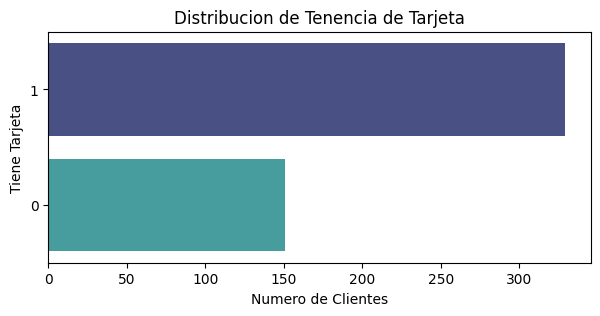

In [204]:
# Grafico de barras
plt.figure(figsize=(7, 3))
sns.countplot(data=X_train, y='tiene_tarjeta', order=X_train['tiene_tarjeta'].value_counts().index, palette='mako')
plt.title("Distribucion de Tenencia de Tarjeta")
plt.xlabel("Numero de Clientes")
plt.ylabel("Tiene Tarjeta")
plt.show()

V (Visualización): Observo qué parte de clientes dispone de tarjeta bancaria activa.

H (Hallazgo): Compruebo que la mayoría de los clientes sí tiene tarjeta. Veo que los datos están bien guardados con ceros y unos, y no encuentro ningún dato nulo ni erróneo.

A (Acción para Preprocesamiento): No aplicaré ningún cambio ni limpieza porque la columna ya está lista y codificada con ceros y unos.

**Columna Comentarios Cliente**


In [205]:
# Inspeccionar valores únicos
print("Valores distintos:", X_train['comentarios_cliente'].unique())
print("Número de categorías:", X_train['comentarios_cliente'].nunique())

# Porcentaje de aparición de cada categoría
X_train['comentarios_cliente'].value_counts(dropna=False, normalize=True) * 100

Valores distintos: [nan 'Desea cancelar cuenta de ahorros'
 'Problemas reiterados con la tarjeta'
 'Cliente muy descontento con comisiones'
 'Solicita atencion telefonica urgente'
 'Excelente trato en oficina de Caceres']
Número de categorías: 5


,proportion
comentarios_cliente,
NaN,98.958333
Desea cancelar cuenta de ahorros,0.208333
Problemas reiterados con la tarjeta,0.208333
Cliente muy descontento con comisiones,0.208333
Solicita atencion telefonica urgente,0.208333
Excelente trato en oficina de Caceres,0.208333


/tmp/ipykernel_3802/490770313.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=X_train, y='comentarios_cliente', order=X_train['comentarios_cliente'].value_counts().index, palette='mako')


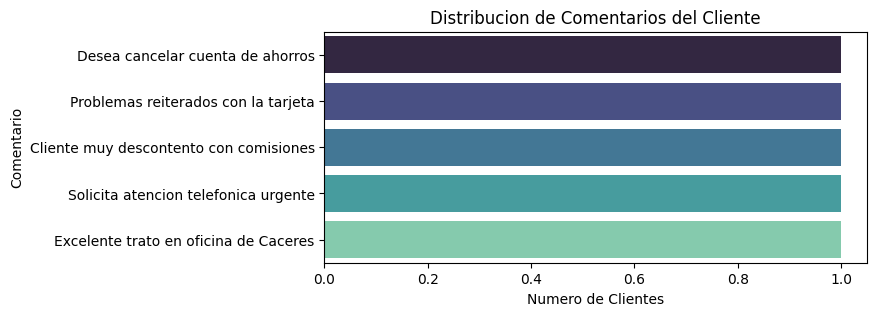

In [206]:
# Grafico de barras
plt.figure(figsize=(7, 3))
sns.countplot(data=X_train, y='comentarios_cliente', order=X_train['comentarios_cliente'].value_counts().index, palette='mako')
plt.title("Distribucion de Comentarios del Cliente")
plt.xlabel("Numero de Clientes")
plt.ylabel("Comentario")
plt.show()

V (Visualización): Observo qué tipo de comentarios en texto libre han dejado los clientes.

H (Hallazgo): Descubro que la mayoría de las filas están vacías, ya que solo 5 clientes en total llegaron a escribir algo. No dispongo de información suficiente como para saber patrones.

A (Acción para Preprocesamiento): Descartaré y eliminaré esta columna directamente porque casi todo son valores nulos y no aportaría nada.

**Columna Motivo Cancelación**


In [207]:
# Inspeccionar valores únicos
print("Valores distintos:", X_train['motivo_cancelacion'].unique())
print("Número de categorías:", X_train['motivo_cancelacion'].nunique())

# Porcentaje de aparición de cada categoría
X_train['motivo_cancelacion'].value_counts(dropna=False, normalize=True) * 100

Valores distintos: [nan 'Mala atencion' 'Mejor oferta competidor' 'Comisiones abusivas'
 'Cambio de residencia']
Número de categorías: 4


,proportion
motivo_cancelacion,
NaN,59.166667
Mejor oferta competidor,10.833333
Comisiones abusivas,10.416667
Cambio de residencia,10.416667
Mala atencion,9.166667


/tmp/ipykernel_3802/1267285458.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=X_train, y='motivo_cancelacion', order=X_train['motivo_cancelacion'].value_counts().index, palette='mako')


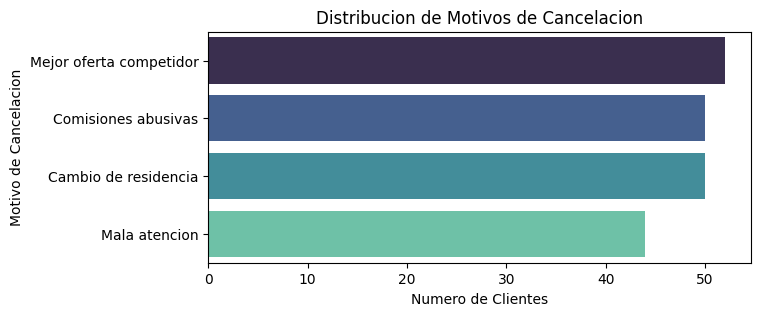

In [208]:
# Grafico de barras
plt.figure(figsize=(7, 3))
sns.countplot(data=X_train, y='motivo_cancelacion', order=X_train['motivo_cancelacion'].value_counts().index, palette='mako')
plt.title("Distribucion de Motivos de Cancelacion")
plt.xlabel("Numero de Clientes")
plt.ylabel("Motivo de Cancelacion")
plt.show()

V (Visualización): Observo cuáles son las razones principales por las que los clientes cancelaron su cuenta.

H (Hallazgo): Veo que más de la mitad de las filas están vacías porque son de los clientes que continúan en el banco. En los que sí se fueron, veo que los motivos se reparten entre mejor oferta de la competencia, comisiones altas, cambio de residencia o mala atención. Me doy cuenta de que este dato solo existe cuando el cliente ya se ha ido.

A (Acción para Preprocesamiento): Eliminaré esta columna antes de entrenar el modelo, porque si la utilizo estaría haciendo trampa al saber qué cliente va a abandonar.

## Análisis de la Variable Objetivo


**Columna Abandono**


In [209]:
# Inspeccionar valores únicos de la variable objetivo
print("Valores distintos:", Y_train.unique())
print("Número de categorías:", Y_train.nunique())

# Frecuencia absoluta y porcentaje de cada clase
Y_train.value_counts(dropna=False, normalize=True) * 100

Valores distintos: [0 1]
Número de categorías: 2


,proportion
abandono,
0,52.5
1,47.5


/tmp/ipykernel_3802/3266154284.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df_temp, y='abandono', order=df_temp['abandono'].value_counts().index, palette='mako')


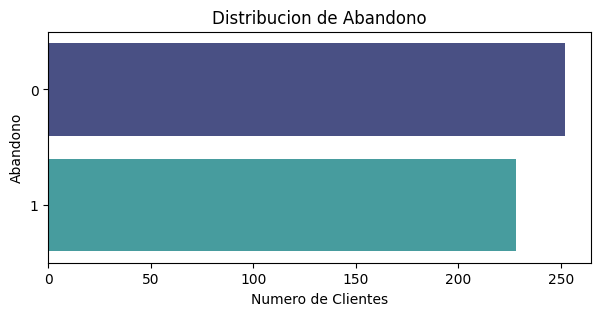

In [210]:
# Grafico de barras de la variable objetivo
df_temp = X_train.assign(abandono=Y_train)
plt.figure(figsize=(7, 3))
sns.countplot(data=df_temp, y='abandono', order=df_temp['abandono'].value_counts().index, palette='mako')
plt.title("Distribucion de Abandono")
plt.xlabel("Numero de Clientes")
plt.ylabel("Abandono")
plt.show()

V (Visualización): Observo cómo se reparten los clientes que se quedan y los que se marchan del banco.

H (Hallazgo): Compruebo que los clientes fieles y los que abandonan están prácticamente igualados a la mitad. Además, veo que todos los registros son ceros o unos y no encuentro ningún valor nulo ni erróneo.

A (Acción para Preprocesamiento): No necesito hacer ninguna limpieza ni relleno porque la variable objetivo está lista. Al estar las dos opciones bien repartidas, el modelo podrá aprender de ambos casos por igual.

# Fase 3: Estudio Bivariante y Multivariante

## Análisis Bivariante Numérica vs Variable Objetivo


**Columna Saldo_cuenta**

/tmp/ipykernel_3802/2063296328.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


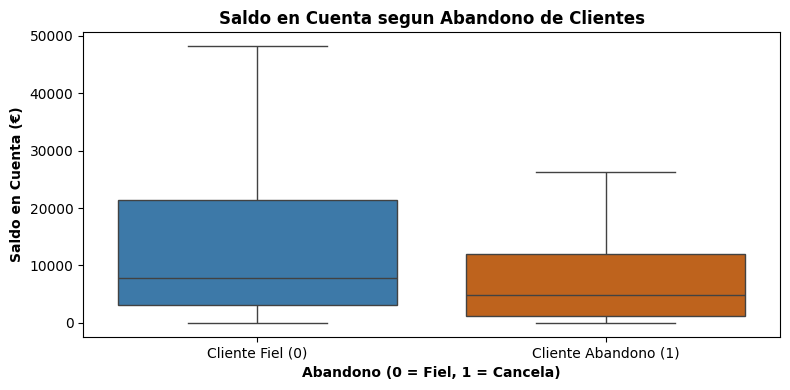

In [211]:
# Diagrama de cajas (Boxplot) comparativo segun abandono
plt.figure(figsize=(8, 4))
sns.boxplot(
    data=X_train.assign(abandono=Y_train),
    x='abandono',
    y='saldo_cuenta',
    palette=['#2b7bba', '#d95f02'],
    showfliers=False
)
plt.title("Saldo en Cuenta segun Abandono de Clientes", fontsize=12, fontweight='bold')
plt.xlabel("Abandono (0 = Fiel, 1 = Cancela)", fontweight='bold')
plt.ylabel("Saldo en Cuenta (€)", fontweight='bold')
plt.xticks([0, 1], ['Cliente Fiel (0)', 'Cliente Abandono (1)'])
plt.tight_layout()
plt.show()

V (Visualización): Observo si tener más o menos dinero en la cuenta influye en que un cliente se marche o se quede.

H (Hallazgo visual): Veo que los clientes fieles suelen tener más dinero guardado, con una mediana de saldo de unos 7.600 €, mientras que en los que se van baja a unos 5.000 €. Noto además que los saldos más altos pertenecen casi siempre a clientes que se quedan.

A (Acción para Preprocesamiento): Me quedo con esta columna y escalaré los importes más altos con un método robusto para que no desbalanceen el aprendizaje del modelo.

**Columna Antiguedad_meses**

/tmp/ipykernel_3802/1078234359.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


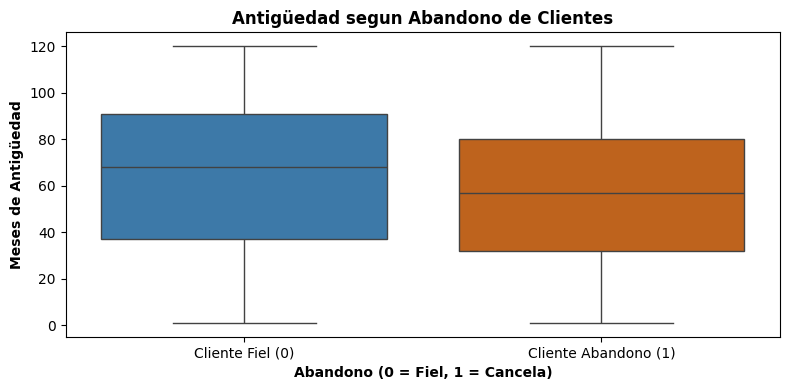

In [212]:
# Diagrama de cajas (Boxplot) comparativo segun abandono
plt.figure(figsize=(8, 4))
sns.boxplot(
    data=X_train.assign(abandono=Y_train),
    x='abandono',
    y='antiguedad_meses',
    palette=['#2b7bba', '#d95f02'],
    showfliers=False
)
plt.title("Antigüedad segun Abandono de Clientes", fontsize=12, fontweight='bold')
plt.xlabel("Abandono (0 = Fiel, 1 = Cancela)", fontweight='bold')
plt.ylabel("Meses de Antigüedad", fontweight='bold')
plt.xticks([0, 1], ['Cliente Fiel (0)', 'Cliente Abandono (1)'])
plt.tight_layout()
plt.show()

V (Visualización): Observo si llevar más o menos tiempo en el banco influye en que un cliente se vaya o se quede.

H (Hallazgo visual): Veo que los clientes fieles llevan algo más de tiempo con nosotros, con una mediana de 68 meses frente a 57 meses en los que deciden marcharse. Aunque noto que los que llevan ya tiempo se quedan un poco más, las dos se parecen bastante, así que el tiempo no me vale para asegurar si alguien se marchará.

A (Acción para Preprocesamiento): Mantengo la columna en el análisis, rellenaré las 5 filas vacías con la mediana y puedo probar a agrupar los meses por antigüedad para ver si los clientes nuevos tienen comportamientos diferentes.

**Columna Edad**

/tmp/ipykernel_3802/2559867952.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


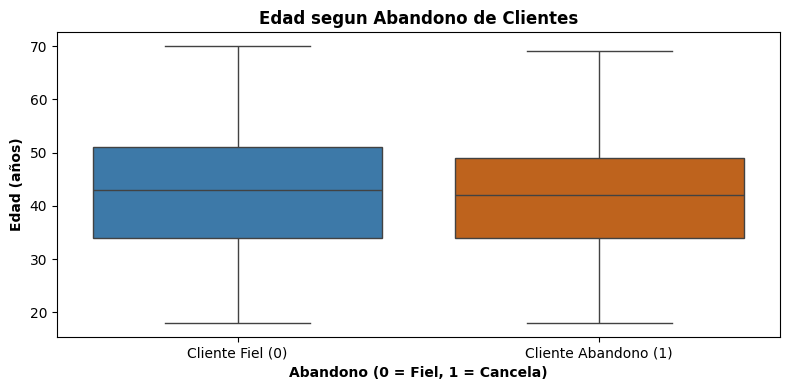

In [213]:
# Diagrama de cajas (Boxplot) comparativo segun abandono
plt.figure(figsize=(8, 4))
sns.boxplot(
    data=X_train.assign(abandono=Y_train),
    x='abandono',
    y='edad',
    palette=['#2b7bba', '#d95f02'],
    showfliers=False
)
plt.title("Edad segun Abandono de Clientes", fontsize=12, fontweight='bold')
plt.xlabel("Abandono (0 = Fiel, 1 = Cancela)", fontweight='bold')
plt.ylabel("Edad (años)", fontweight='bold')
plt.xticks([0, 1], ['Cliente Fiel (0)', 'Cliente Abandono (1)'])
plt.tight_layout()
plt.show()

V (Visualización): Observo si los clientes más jóvenes o más mayores tienen mayor tendencia a marcharse del banco.

H (Hallazgo visual): Al comparar los dos grupos, veo que los clientes fieles y los que se van tienen prácticamente las mismas edades. En los dos la mediana está en torno a los 42 o 43 años y la gran mayoría tiene entre 34 y 50 años. Mirando la edad, veo que no me sirve para distinguir quién se va.

A (Acción para Preprocesamiento): Borraré la edad imposible de 999 años, rellenaré los huecos vacíos con la media y guardaré la columna por si el modelo detecta patrones.

## Análisis Bivariante Categórica vs Variable Objetivo


**Columna Nivel_satisfaccion**

In [214]:
# Tabla de contingencia en porcentaje por nivel de satisfaccion
tabla_relacion = pd.crosstab(
    X_train['nivel_satisfaccion'],
    Y_train,
    normalize='index'
) * 100
print(tabla_relacion.round(2))

abandono                0      1
nivel_satisfaccion              
Alto                80.77  19.23
Bajo                24.75  75.25
Medio               57.89  42.11
Muy Alto            92.86   7.14
Muy Bajo             8.06  91.94


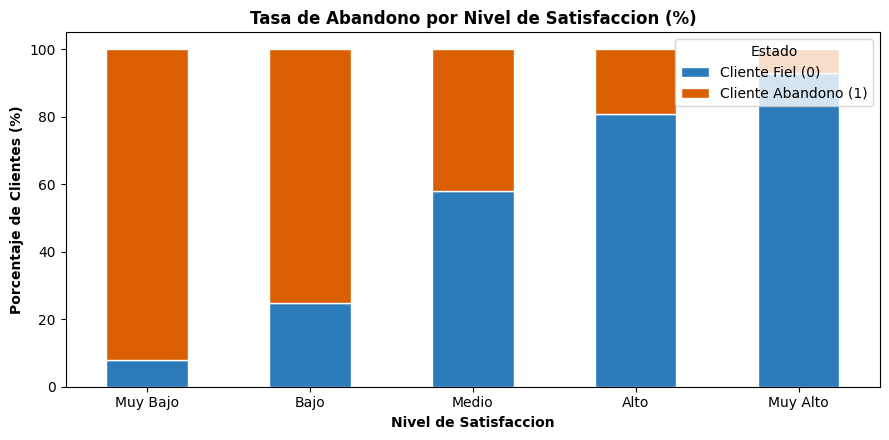

In [215]:
# Grafico de barras apiladas al 100%
orden_satisfaccion = ['Muy Bajo', 'Bajo', 'Medio', 'Alto', 'Muy Alto']
tabla_relacion.reindex(orden_satisfaccion).plot(
    kind='bar',
    stacked=True,
    color=['#2b7bba', '#d95f02'],
    figsize=(9, 4.5),
    edgecolor='white'
)
plt.title("Tasa de Abandono por Nivel de Satisfaccion (%)", fontsize=12, fontweight='bold')
plt.xlabel("Nivel de Satisfaccion", fontweight='bold')
plt.ylabel("Porcentaje de Clientes (%)", fontweight='bold')
plt.legend(['Cliente Fiel (0)', 'Cliente Abandono (1)'], title='Estado', loc='upper right')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

V (Visualización): Observo si los clientes descontentos se marchan del banco más que los que están satisfechos.

H (Hallazgo visual): Veo que el grado de satisfacción influye de forma decisiva. De los clientes con satisfacción muy baja, veo que se marcha el 92%. A medida que aumenta la satisfacción, veo que las personas tienden a no irse: con satisfacción alta solo se va el 18% y con muy alta apenas un 6%.

A (Acción para Preprocesamiento): Guardo esta columna porque me sirve para saber si un cliente se va o no y transformaré los niveles en valores numéricos ordenados del 1 al 5.

**Columna Tipo_cuenta**

In [216]:
# Tabla de contingencia en porcentaje por tipo de cuenta
tabla_relacion = pd.crosstab(
    X_train['tipo_cuenta'],
    Y_train,
    normalize='index'
) * 100
print(tabla_relacion.round(2))

abandono          0       1
tipo_cuenta                
 Ahorro      100.00    0.00
?              0.00  100.00
AHORRO       100.00    0.00
Ahorro        46.00   54.00
Corriente     53.33   46.67
Inversion     68.42   31.58
Nomina        57.32   42.68
nomina       100.00    0.00


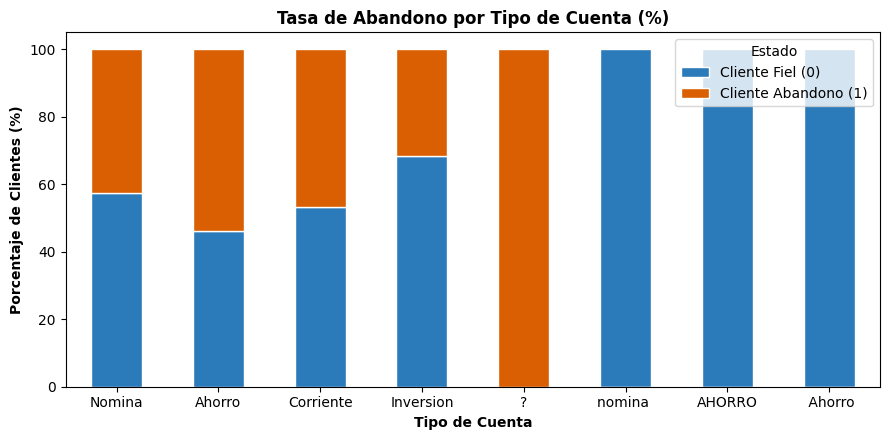

In [217]:
# Grafico de barras apiladas al 100%
cuenta_tipos = ['Nomina', 'Ahorro', 'Corriente', 'Inversion', '?', 'nomina ', 'AHORRO', ' Ahorro']
tabla_relacion.reindex(cuenta_tipos).plot(
    kind='bar',
    stacked=True,
    color=['#2b7bba', '#d95f02'],
    figsize=(9, 4.5),
    edgecolor='white'
)
plt.title("Tasa de Abandono por Tipo de Cuenta (%)", fontsize=12, fontweight='bold')
plt.xlabel("Tipo de Cuenta", fontweight='bold')
plt.ylabel("Porcentaje de Clientes (%)", fontweight='bold')
plt.legend(['Cliente Fiel (0)', 'Cliente Abandono (1)'], title='Estado', loc='upper right')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

V (Visualización): Observo con qué tipo de cuenta se marcha más la gente.

H (Hallazgo visual): Veo que la cuenta de Ahorro es la que mayor riesgo tiene, perdiendo a más de la mitad de sus clientes. En la cuenta Corriente las bajas están en el 47%, en Nómina en el 43% y en Inversión en solo el 32%, siendo los clientes más fieles. Noto también que los clientes con fallos en el texto acabaron abandonando el banco.

A (Acción para Preprocesamiento): Corregiré las palabras mal escritas, unificaré los nombres repetidos y cambiaré el signo de interrogación por la cuenta más común antes de generar columnas independientes para cada cuenta.

**Columna Motivo_cancelacion**

In [218]:
# Tabla de contingencia en porcentaje por motivo de cancelacion
tabla_relacion = pd.crosstab(
    X_train['motivo_cancelacion'],
    Y_train,
    normalize='index'
) * 100
print(tabla_relacion.round(2))

abandono                     1
motivo_cancelacion            
Cambio de residencia     100.0
Comisiones abusivas      100.0
Mala atencion            100.0
Mejor oferta competidor  100.0


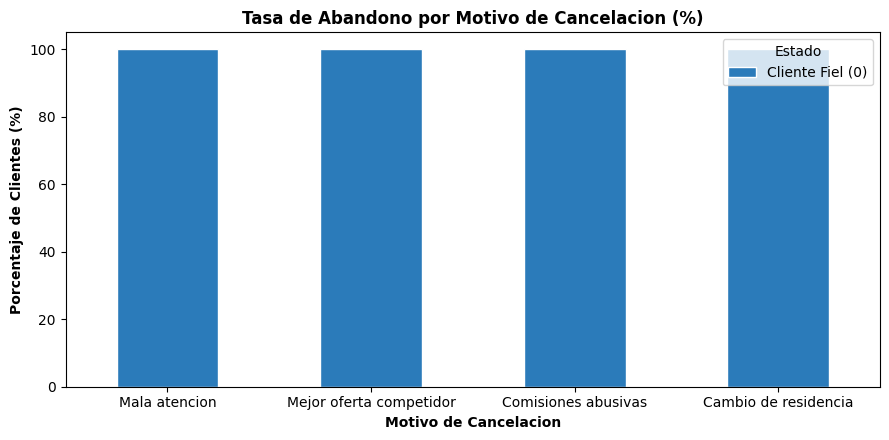

In [219]:
# Grafico de barras apiladas al 100%
cancelacion_motivos = ['Mala atencion', 'Mejor oferta competidor', 'Comisiones abusivas', 'Cambio de residencia']
tabla_relacion.reindex(cancelacion_motivos).plot(
    kind='bar',
    stacked=True,
    color=['#2b7bba', '#d95f02'],
    figsize=(9, 4.5),
    edgecolor='white'
)
plt.title("Tasa de Abandono por Motivo de Cancelacion (%)", fontsize=12, fontweight='bold')
plt.xlabel("Motivo de Cancelacion", fontweight='bold')
plt.ylabel("Porcentaje de Clientes (%)", fontweight='bold')
plt.legend(['Cliente Fiel (0)', 'Cliente Abandono (1)'], title='Estado', loc='upper right')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

V (Visualización): Observo qué motivos dan los clientes cuando deciden marcharse.

H (Hallazgo visual): Veo que todos los clientes que tienen un motivo registrado ya han abandonado. Los clientes fieles tienen esta casilla vacía porque siguen con nosotros. Me doy cuenta de que este campo solo se rellena cuando la cuenta ya está cancelada.

A (Acción para Preprocesamiento): Elimino esta columna por completo porque si la utilizara estaría haciendo trampa y falsearía los resultados al conocer antes quién se ha marchado.

## Análisis Multicolinealidad Numérica

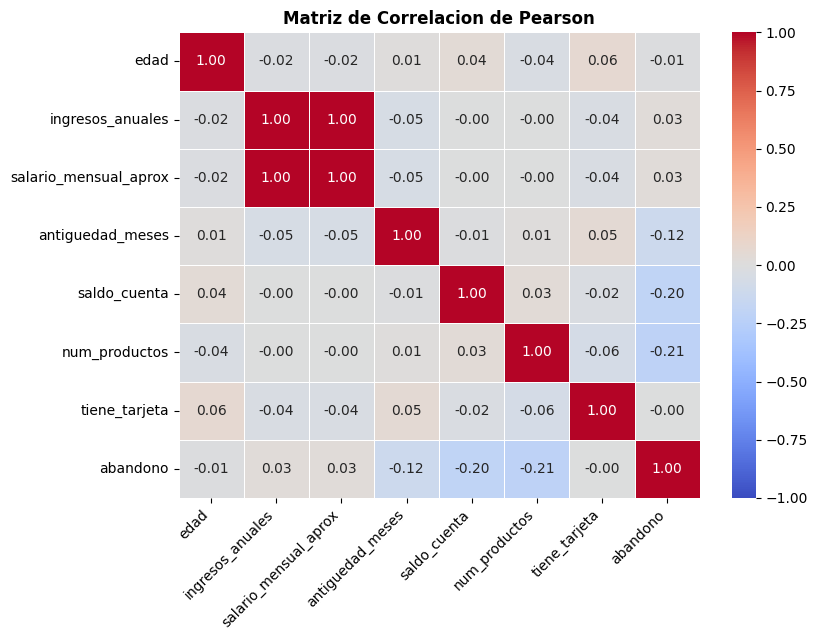

In [220]:
# Matriz de correlacion de Pearson y mapa de calor
df_num = X_train.select_dtypes(include='number').assign(abandono=Y_train)
matriz_corr = df_num.corr()

plt.figure(figsize=(8.5, 6.5))
sns.heatmap(
    matriz_corr,
    annot=True,
    fmt='.2f',
    cmap='coolwarm',
    vmin=-1,
    vmax=1,
    linewidths=0.5
)
plt.title("Matriz de Correlacion de Pearson", fontsize=12, fontweight='bold')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

**Columnas que quito:**
* salario_mensual_aprox: Tiene una relación de 1,00 con los ingresos anuales porque es exactamente el mismo dato pero dividido entre 12. La quito para no tener información repetida dos veces.

**Columnas que me guardo:**
* ingresos_anuales: La guardo como la columna principal para saber cuánto dinero gana el cliente.
* saldo_cuenta, antiguedad_meses y num_productos: Me las quedo porque ayudan a saber si un cliente se va.
* edad y tiene_tarjeta: Me la quedo porque el modelo puede encontrar cosas útiles al combinarlas con otras columnas.


# Conclusiones y Decisiones para el Preprocesamiento


| Variable | Tipo de característica | Poder Predictivo Observado | Decisión Técnica |
| :--- | :--- | :--- | :--- |
| **id_cliente** | Identificador | Ninguna porque solo es un código administrativo | Quitar la columna porque solo identifica al cliente y no sirve para aprender. |
| **edad** | Numérica continua | Casi nula ya que fieles y abandonos tienen edades muy similares | Borrar la edad imposible de 999 años, rellenar los huecos vacíos con la mediana y guardarla por si sirve por grupos de edad. |
| **ingresos_anuales** | Numérica continua | Muy débil de forma directa | Rellenar los huecos vacíos con la mediana, revisar los que tienen 0 € y retocar los sueldos más altos. |
| **salario_mensual_aprox** | Numérica continua | Totalmente repetida con los ingresos anuales | Quitar la columna porque dice exactamente lo mismo que los ingresos anuales. |
| **antiguedad_meses** | Numérica discreta | Los clientes más antiguos tienden a quedarse algo más | Rellenar las 5 filas vacías con la mediana de la antigüedad para no perder clientes. |
| **saldo_cuenta** | Numérica continua | Clave porque los clientes con más saldo casi siempre se quedan | No hay que rellenar nada y solo ajustar los saldos más ricos para no descompensar. |
| **nivel_estudios** | Categórica ordinal | Apenas influye en la decisión de marcharse | Rellenar los huecos vacíos con Grado y pasar los estudios a números ordenados de menor a mayor. |
| **tipo_cuenta** | Categórica nominal | Influye bastante ya que Ahorro pierde un 54% de clientes mientras que Inversión solo pierde un 32% | Arreglar faltas y espacios, cambiar el signo de interrogación por Corriente y convertir cada cuenta en columnas separadas. |
| **nivel_satisfaccion** | Categórica ordinal | Muy decisiva ya que el 92% de los muy descontentos cancela la cuenta | Guardar con máxima prioridad y pasar las respuestas a números del 1 al 5. |
| **num_productos** | Numérica discreta | Influye claramente porque cuantos más productos tienen contratados menos se van | No hay que tocar nada porque los números del 1 al 4 están correctos. |
| **tiene_tarjeta** | Categórica binaria | No influye porque la proporción de tarjetas es idéntica en ambos grupos | No hay que tocar nada porque ya viene lista con ceros y unos. |
| **canal_preferido** | Categórica nominal | Muestra pequeñas diferencias según la vía de contacto elegida | No hay que rellenar nada y poner cada canal en una columna distinta. |
| **comentarios_cliente** | Categórica nominal | No se puede usar porque casi todas las filas están vacías | Quitar la columna del modelo. |
| **motivo_cancelacion** | Categórica nominal | Es trampa porque solo lo rellenan los que ya se han ido | Quitar la columna para no falsear los resultados. |
| **abandono** | Categórica binaria | Es la variable objetivo y representa lo que quiero predecir | No hay que tocar nada porque está completa, equilibrada y lista con ceros y unos. |
